<a href="https://colab.research.google.com/github/mohamadabelto20-code/Mohamadabelto.github.io/blob/main/analisis_statistika_industri_tk1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas Kelompok 5 — Statistika Industri (BBK2GAB3)
## Visualisasi & Deskripsi Data

**Dataset:** *Impact of Social Media on Life* (Kaggle — harishyadav0506)
**Populasi:** 4.500 siswa (SMA s.d. pascasarjana, usia 15–26 tahun)
**Variabel dependen:** `Overall_Impact` (Beneficial / Neutral / Negative)



---
## Persiapan — Import Library


In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

---
## TASK 2 — Deskripsi & Cleansing Data

### 2.1 Memuat data mentah

In [37]:
raw = pd.read_csv("Social_media_impact_on_life.csv")
print("Ukuran data mentah:", raw.shape)
raw.head()

Ukuran data mentah: (4500, 16)


,Student_ID,Age,Gender,Academic_Level,Primary_Platform,Daily_Usage_Hours,Weekend_Extra_Hours,Device_Type,Sleep_Duration_Hours,Sleep_Quality_Score,Late_Night_Usage,Social_Comparison_Frequency,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Overall_Impact
0,STU_2024000,19,Female,Undergraduate,Snapchat,7.5,1.5,Smartphone,5.9,2,True,Always,20.0,73,2.73,Neutral
1,STU_2024001,19,Female,Undergraduate,Instagram,4.6,1.3,Smartphone,7.9,3,True,Sometimes,17.0,90,3.21,Beneficial
2,STU_2024002,17,Female,High School,TikTok,10.9,1.7,Smartphone,5.2,1,True,Frequently,18.0,70,3.00,Neutral
3,STU_2024003,16,Female,High School,YouTube,6.0,2.3,Tablet,7.6,4,True,Sometimes,15.0,82,3.42,Beneficial
4,STU_2024004,17,Male,High School,LinkedIn,3.3,2.6,Smartphone,7.6,4,True,Never,16.0,84,3.41,Beneficial


In [38]:
# Cek kondisi awal: nilai kosong per kolom dan duplikat
print("Nilai kosong per kolom (yang > 0):")
print(raw.isna().sum()[raw.isna().sum() > 0])
print("\nBaris duplikat:", raw.duplicated().sum())
print("Student_ID ganda:", raw.duplicated(subset=["Student_ID"]).sum())

Nilai kosong per kolom (yang > 0):
Perceived_Stress_Score      46
Academic_Performance_GPA    85
dtype: int64

Baris duplikat: 0
Student_ID ganda: 0


### 2.2 Cleansing


In [39]:
df = raw.copy()

# 1) Drop kolom identifier
df = df.drop(columns=["Student_ID"])

# 2) Hapus duplikat
df = df.drop_duplicates()

# 3) Imputasi mean untuk nilai kosong pada kolom numerik
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
for c in num_cols:
    if df[c].isna().any():
        df[c] = df[c].fillna(df[c].mean())

print("Ukuran setelah cleansing:", df.shape)
print("Total nilai kosong tersisa:", int(df.isna().sum().sum()))
df.head()

Ukuran setelah cleansing: (4500, 15)
Total nilai kosong tersisa: 0


,Age,Gender,Academic_Level,Primary_Platform,Daily_Usage_Hours,Weekend_Extra_Hours,Device_Type,Sleep_Duration_Hours,Sleep_Quality_Score,Late_Night_Usage,Social_Comparison_Frequency,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Overall_Impact
0,19,Female,Undergraduate,Snapchat,7.5,1.5,Smartphone,5.9,2,True,Always,20.0,73,2.73,Neutral
1,19,Female,Undergraduate,Instagram,4.6,1.3,Smartphone,7.9,3,True,Sometimes,17.0,90,3.21,Beneficial
2,17,Female,High School,TikTok,10.9,1.7,Smartphone,5.2,1,True,Frequently,18.0,70,3.00,Neutral
3,16,Female,High School,YouTube,6.0,2.3,Tablet,7.6,4,True,Sometimes,15.0,82,3.42,Beneficial
4,17,Male,High School,LinkedIn,3.3,2.6,Smartphone,7.6,4,True,Never,16.0,84,3.41,Beneficial


In [40]:
# Frekuensi variabel kategorik
cat_cols = [c for c in df.columns if c not in num_cols]
for c in cat_cols:
    print(f"\n== {c} ==")
    print(df[c].value_counts())


== Gender ==
Gender
Female               2234
Male                 2051
Non-Binary            122
Prefer not to say      93
Name: count, dtype: int64

== Academic_Level ==
Academic_Level
Undergraduate    2777
High School      1477
Postgraduate      246
Name: count, dtype: int64

== Primary_Platform ==
Primary_Platform
Instagram      1453
TikTok         1226
YouTube         818
Snapchat        472
Reddit          229
X (Twitter)     206
LinkedIn         96
Name: count, dtype: int64

== Device_Type ==
Device_Type
Smartphone    3775
Laptop/PC      596
Tablet         129
Name: count, dtype: int64

== Late_Night_Usage ==
Late_Night_Usage
True     2644
False    1856
Name: count, dtype: int64

== Social_Comparison_Frequency ==
Social_Comparison_Frequency
Sometimes     1594
Frequently    1248
Rarely         766
Always         632
Never          260
Name: count, dtype: int64

== Overall_Impact ==
Overall_Impact
Beneficial    3681
Neutral        654
Negative       165
Name: count, dtype: int64


---
## TASK 3 — Statistika Deskriptif
Tabel lengkap: mean, std, min, Q1, median, Q3, max, IQR, jumlah outlier (aturan 1,5×IQR), skewness, dan koefisien variasi (CV).

In [41]:
desc = df[num_cols].describe(percentiles=[0.25, 0.5, 0.75]).T
desc["variance"] = df[num_cols].var()
desc["skewness"] = df[num_cols].skew()
desc["IQR"] = desc["75%"] - desc["25%"]
bawah = desc["25%"] - 1.5 * desc["IQR"]
atas = desc["75%"] + 1.5 * desc["IQR"]
desc["jumlah_outlier"] = [int(((df[c] < bawah[c]) | (df[c] > atas[c])).sum()) for c in num_cols]
desc["CV_%"] = desc["std"] / desc["mean"] * 100
desc.round(3)

,count,mean,std,min,25%,50%,75%,max,variance,skewness,IQR,jumlah_outlier,CV_%
Age,4500.0,18.703,1.981,15.0,17.0,19.00,20.00,26.0,3.925,0.688,3.00,51,10.593
Daily_Usage_Hours,4500.0,5.296,2.604,0.9,3.4,4.70,6.60,14.0,6.783,1.135,3.20,162,49.179
Weekend_Extra_Hours,4500.0,1.797,0.699,0.0,1.3,1.80,2.30,4.5,0.489,0.023,1.00,10,38.915
Sleep_Duration_Hours,4500.0,6.701,1.190,3.0,6.0,6.80,7.50,10.5,1.416,-0.343,1.50,72,17.758
Sleep_Quality_Score,4500.0,2.472,1.030,1.0,2.0,3.00,3.00,5.0,1.062,0.162,1.00,91,41.686
Perceived_Stress_Score,4500.0,13.512,7.037,0.0,9.0,13.00,18.00,40.0,49.514,0.585,9.00,75,52.076
Mental_Health_Index,4500.0,79.873,12.876,32.0,72.0,82.00,89.00,98.0,165.793,-0.810,17.00,85,16.121
Academic_Performance_GPA,4500.0,3.429,0.389,1.9,3.2,3.45,3.72,4.0,0.151,-0.639,0.52,68,11.342


In [42]:
# Korelasi antar variabel numerik
corr = df[num_cols].corr()
corr.round(2)

,Age,Daily_Usage_Hours,Weekend_Extra_Hours,Sleep_Duration_Hours,Sleep_Quality_Score,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA
Age,1.00,-0.03,0.00,0.01,0.03,-0.02,0.02,0.03
Daily_Usage_Hours,-0.03,1.00,-0.01,-0.72,-0.68,0.75,-0.85,-0.70
Weekend_Extra_Hours,0.00,-0.01,1.00,0.02,0.01,0.00,0.00,0.01
Sleep_Duration_Hours,0.01,-0.72,0.02,1.00,0.75,-0.66,0.77,0.59
Sleep_Quality_Score,0.03,-0.68,0.01,0.75,1.00,-0.57,0.66,0.52
Perceived_Stress_Score,-0.02,0.75,0.00,-0.66,-0.57,1.00,-0.77,-0.64
Mental_Health_Index,0.02,-0.85,0.00,0.77,0.66,-0.77,1.00,0.65
Academic_Performance_GPA,0.03,-0.70,0.01,0.59,0.52,-0.64,0.65,1.00


In [43]:
# Rata-rata variabel kunci per kelompok Overall_Impact
df.groupby("Overall_Impact")[["Daily_Usage_Hours", "Sleep_Duration_Hours",
    "Perceived_Stress_Score", "Mental_Health_Index",
    "Academic_Performance_GPA"]].mean().round(2)

,Daily_Usage_Hours,Sleep_Duration_Hours,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA
Overall_Impact,,,,,
Beneficial,4.42,7.03,11.18,84.26,3.54
Negative,12.25,4.23,31.01,47.13,2.55
Neutral,8.50,5.48,22.20,63.42,3.00


---
## TASK 4 — Visualisasi Data (data hasil sampling)
Sesuai modul, visualisasi dilakukan terhadap data hasil sampling. Sampel diambil dengan **simple random sampling** n = 500 dari 4.500 populasi (`random_state=42` agar hasil tetap/reproduksibel). Khusus heatmap digunakan populasi penuh.

In [44]:
sample = df.sample(n=500, random_state=42)
print("Ukuran sampel:", sample.shape)

Ukuran sampel: (500, 15)


### 4.1 Diagram Lingkaran — Overall_Impact (variabel dependen)

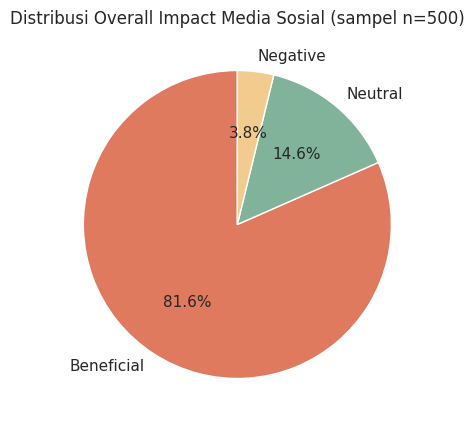

In [45]:
vc = sample["Overall_Impact"].value_counts()
plt.figure(figsize=(6.5, 5))
plt.pie(vc.values, labels=vc.index, autopct="%1.1f%%", startangle=90,
        colors=["#e07a5f", "#81b29a", "#f2cc8f"], textprops={"fontsize": 11})
plt.title("Distribusi Overall Impact Media Sosial (sampel n=500)")
plt.show()

### 4.2 Diagram Batang — Platform Utama

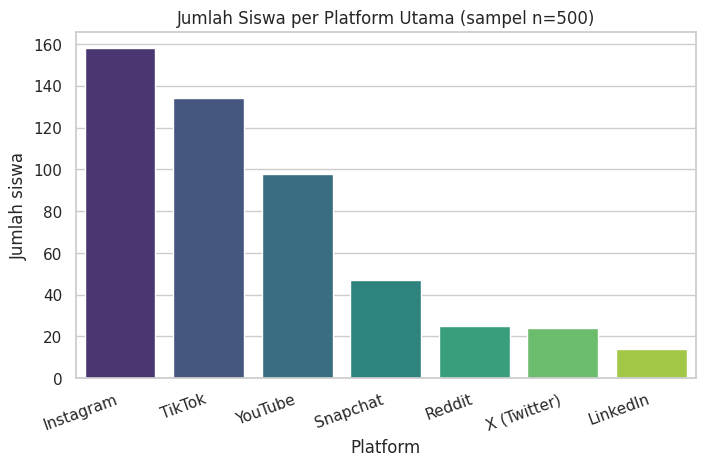

In [46]:
pc = sample["Primary_Platform"].value_counts()
plt.figure(figsize=(8, 4.5))
sns.barplot(x=pc.index, y=pc.values, hue=pc.index, legend=False, palette="viridis")
plt.title("Jumlah Siswa per Platform Utama (sampel n=500)")
plt.xlabel("Platform"); plt.ylabel("Jumlah siswa")
plt.xticks(rotation=20, ha="right")
plt.show()

### 4.3 Diagram Batang — Jenjang Akademik

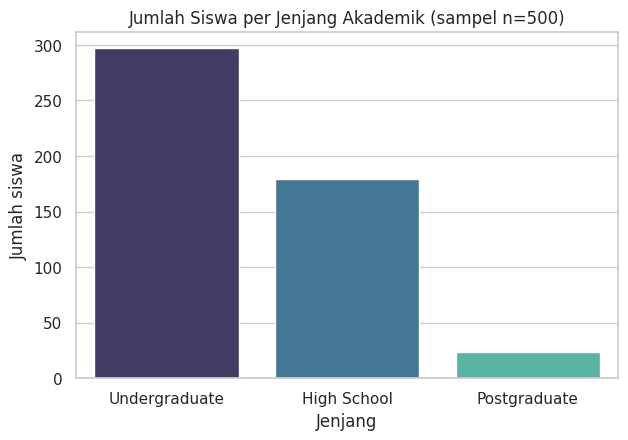

In [47]:
ac = sample["Academic_Level"].value_counts()
plt.figure(figsize=(7, 4.5))
sns.barplot(x=ac.index, y=ac.values, hue=ac.index, legend=False, palette="mako")
plt.title("Jumlah Siswa per Jenjang Akademik (sampel n=500)")
plt.xlabel("Jenjang"); plt.ylabel("Jumlah siswa")
plt.show()

### 4.4 Diagram Garis — Rata-rata Penggunaan menurut Usia

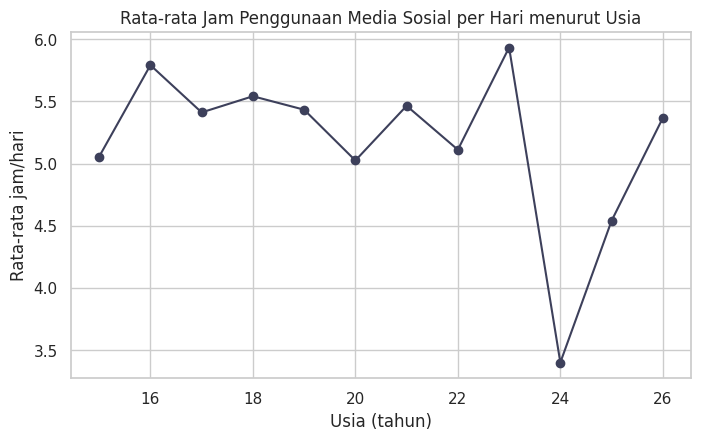

In [48]:
i'm by_age = sample.groupby("Age")["Daily_Usage_Hours"].mean()
plt.figure(figsize=(8, 4.5))
plt.plot(by_age.index, by_age.values, marker="o", color="#3d405b")
plt.title("Rata-rata Jam Penggunaan Media Sosial per Hari menurut Usia")
plt.xlabel("Usia (tahun)"); plt.ylabel("Rata-rata jam/hari")
plt.show()

### 4.5 Histogram — Durasi Penggunaan per Hari

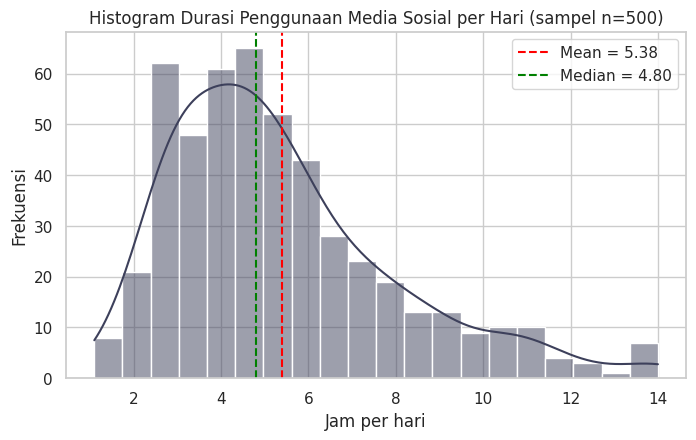

In [49]:
plt.figure(figsize=(8, 4.5))
sns.histplot(sample["Daily_Usage_Hours"], bins=20, kde=True, color="#3d405b")
plt.axvline(sample["Daily_Usage_Hours"].mean(), color="red", linestyle="--",
            label=f"Mean = {sample['Daily_Usage_Hours'].mean():.2f}")
plt.axvline(sample["Daily_Usage_Hours"].median(), color="green", linestyle="--",
            label=f"Median = {sample['Daily_Usage_Hours'].median():.2f}")
plt.title("Histogram Durasi Penggunaan Media Sosial per Hari (sampel n=500)")
plt.xlabel("Jam per hari"); plt.ylabel("Frekuensi"); plt.legend()
plt.show()

### 4.6 Histogram — GPA

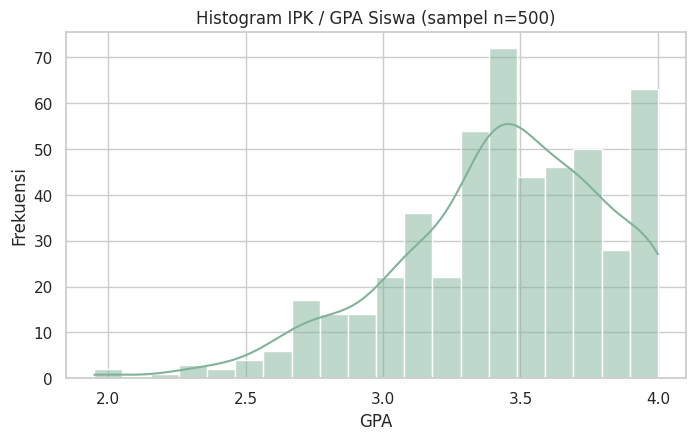

In [50]:
plt.figure(figsize=(8, 4.5))
sns.histplot(sample["Academic_Performance_GPA"], bins=20, kde=True, color="#81b29a")
plt.title("Histogram IPK / GPA Siswa (sampel n=500)")
plt.xlabel("GPA"); plt.ylabel("Frekuensi")
plt.show()

### 4.7 Boxplot — Durasi Penggunaan vs Durasi Tidur

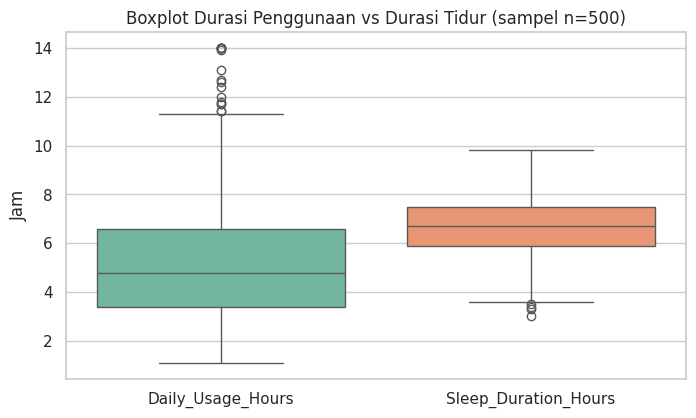

In [51]:
plt.figure(figsize=(8, 4.5))
sns.boxplot(data=sample[["Daily_Usage_Hours", "Sleep_Duration_Hours"]], palette="Set2")
plt.title("Boxplot Durasi Penggunaan vs Durasi Tidur (sampel n=500)")
plt.ylabel("Jam")
plt.show()

### 4.8 Boxplot — GPA menurut Overall_Impact

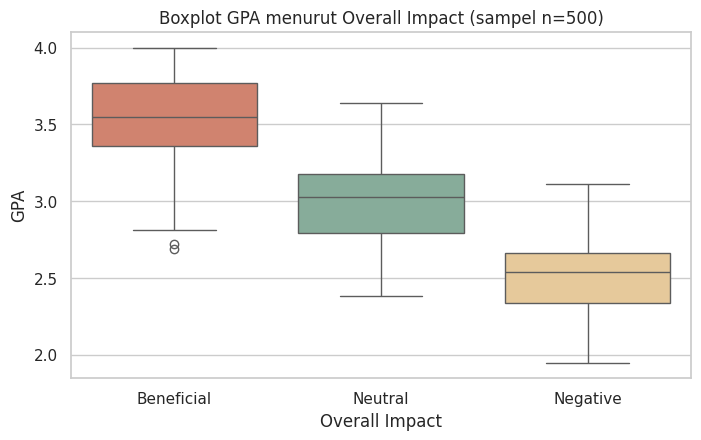

In [52]:
plt.figure(figsize=(8, 4.5))
sns.boxplot(data=sample, x="Overall_Impact", y="Academic_Performance_GPA",
            hue="Overall_Impact", legend=False, palette=["#e07a5f", "#81b29a", "#f2cc8f"])
plt.title("Boxplot GPA menurut Overall Impact (sampel n=500)")
plt.xlabel("Overall Impact"); plt.ylabel("GPA")
plt.show()

### 4.9 Diagram Pencar — Durasi Penggunaan vs GPA

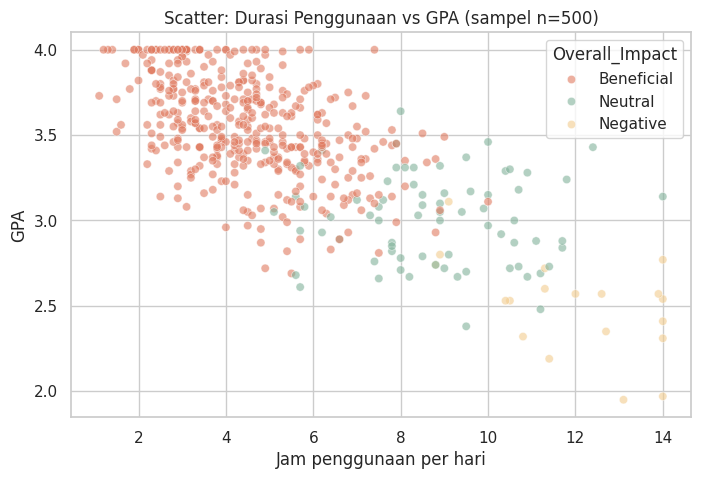

In [53]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=sample, x="Daily_Usage_Hours", y="Academic_Performance_GPA",
                hue="Overall_Impact", alpha=0.6,
                palette=["#e07a5f", "#81b29a", "#f2cc8f"])
plt.title("Scatter: Durasi Penggunaan vs GPA (sampel n=500)")
plt.xlabel("Jam penggunaan per hari"); plt.ylabel("GPA")
plt.show()

### 4.10 Diagram Pencar — Durasi Penggunaan vs Durasi Tidur

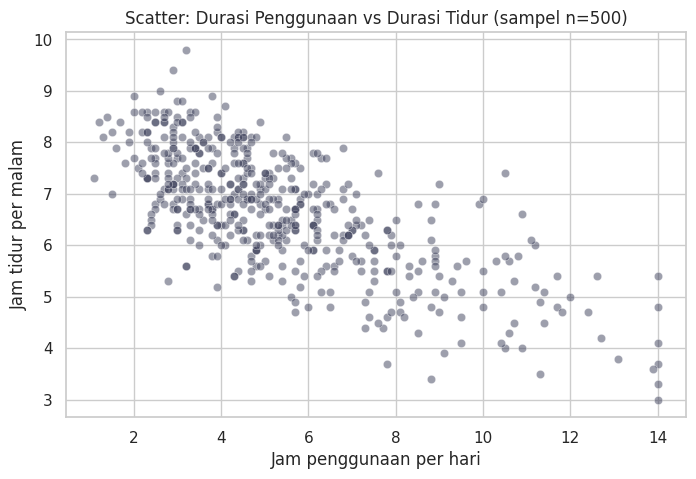

In [54]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=sample, x="Daily_Usage_Hours", y="Sleep_Duration_Hours",
                alpha=0.5, color="#3d405b")
plt.title("Scatter: Durasi Penggunaan vs Durasi Tidur (sampel n=500)")
plt.xlabel("Jam penggunaan per hari"); plt.ylabel("Jam tidur per malam")
plt.show()

### 4.11 Heatmap — Korelasi Antar Variabel Numerik (populasi penuh)

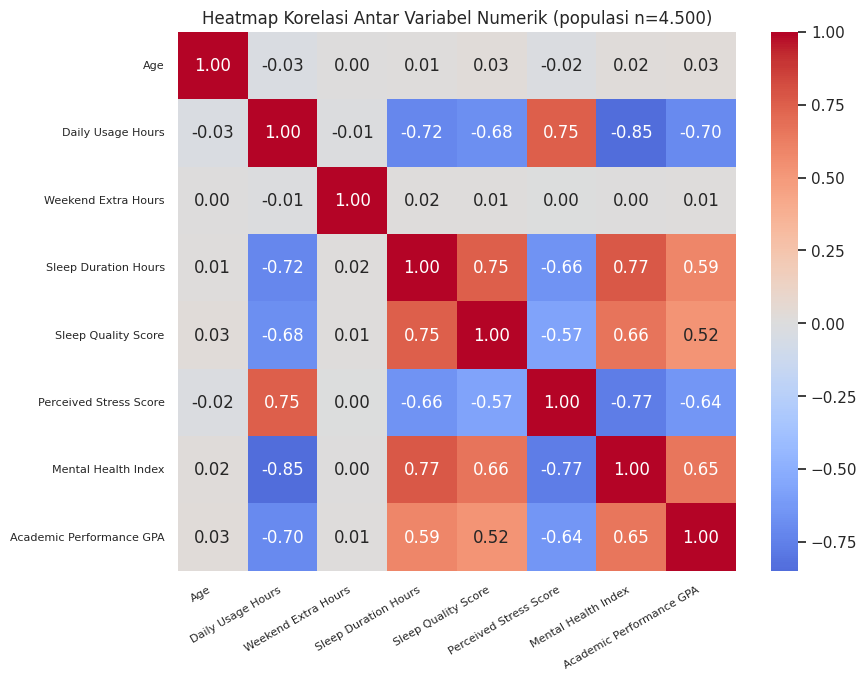

In [55]:
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            xticklabels=[c.replace("_", " ") for c in num_cols],
            yticklabels=[c.replace("_", " ") for c in num_cols])
plt.title("Heatmap Korelasi Antar Variabel Numerik (populasi n=4.500)")
plt.xticks(rotation=30, ha="right", fontsize=8)
plt.yticks(fontsize=8)
plt.show()

# **Uji Normalitas**


File berhasil dimuat: Social_media_impact_on_life.csv
Ukuran data: (4500, 16)


,Student_ID,Age,Gender,Academic_Level,Primary_Platform,Daily_Usage_Hours,Weekend_Extra_Hours,Device_Type,Sleep_Duration_Hours,Sleep_Quality_Score,Late_Night_Usage,Social_Comparison_Frequency,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Overall_Impact
0,STU_2024000,19,Female,Undergraduate,Snapchat,7.5,1.5,Smartphone,5.9,2,True,Always,20.0,73,2.73,Neutral
1,STU_2024001,19,Female,Undergraduate,Instagram,4.6,1.3,Smartphone,7.9,3,True,Sometimes,17.0,90,3.21,Beneficial
2,STU_2024002,17,Female,High School,TikTok,10.9,1.7,Smartphone,5.2,1,True,Frequently,18.0,70,3.00,Neutral
3,STU_2024003,16,Female,High School,YouTube,6.0,2.3,Tablet,7.6,4,True,Sometimes,15.0,82,3.42,Beneficial
4,STU_2024004,17,Male,High School,LinkedIn,3.3,2.6,Smartphone,7.6,4,True,Never,16.0,84,3.41,Beneficial



Variabel numerik yang terdeteksi: ['Age', 'Daily_Usage_Hours', 'Weekend_Extra_Hours', 'Sleep_Duration_Hours', 'Sleep_Quality_Score', 'Perceived_Stress_Score', 'Mental_Health_Index', 'Academic_Performance_GPA']

--- HASIL UJI NORMALITAS AWAL (SHAPIRO-WILK) ---
Variabel: Age | stat=0.9504, p-value=0.0000 -> Tidak Normal (Tolak H0)


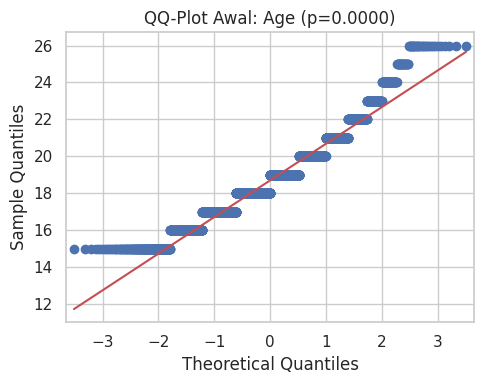

Variabel: Daily_Usage_Hours | stat=0.9177, p-value=0.0000 -> Tidak Normal (Tolak H0)


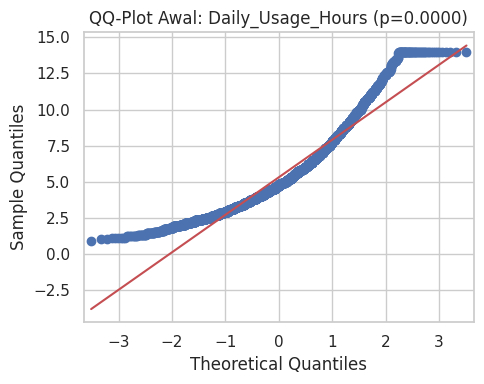

Variabel: Weekend_Extra_Hours | stat=0.9972, p-value=0.0000 -> Tidak Normal (Tolak H0)


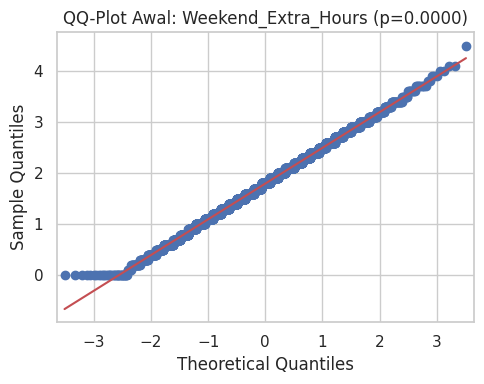

Variabel: Sleep_Duration_Hours | stat=0.9915, p-value=0.0000 -> Tidak Normal (Tolak H0)


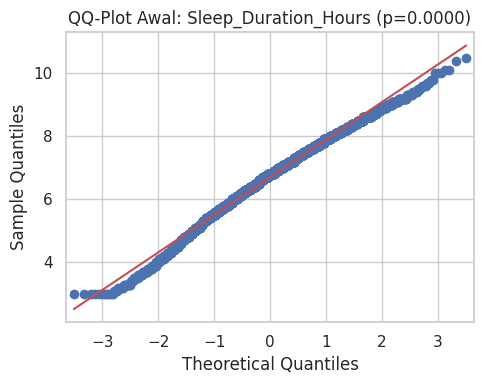

Variabel: Sleep_Quality_Score | stat=0.8964, p-value=0.0000 -> Tidak Normal (Tolak H0)


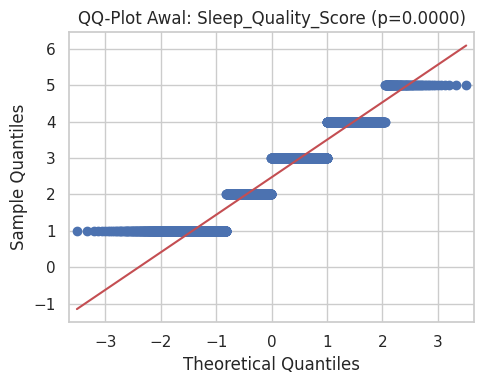

Variabel: Perceived_Stress_Score | stat=0.9771, p-value=0.0000 -> Tidak Normal (Tolak H0)


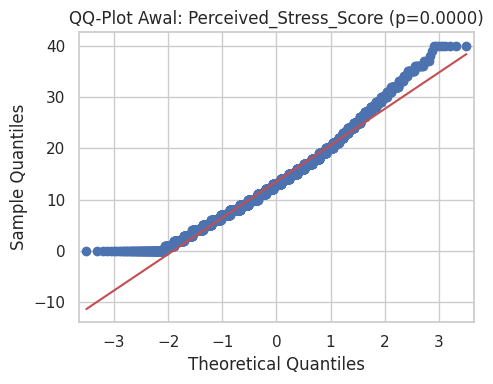

Variabel: Mental_Health_Index | stat=0.9492, p-value=0.0000 -> Tidak Normal (Tolak H0)


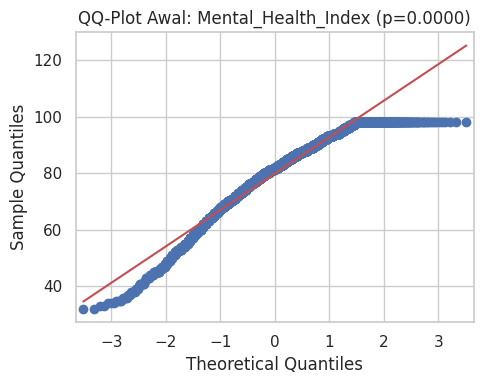

Variabel: Academic_Performance_GPA | stat=0.9626, p-value=0.0000 -> Tidak Normal (Tolak H0)


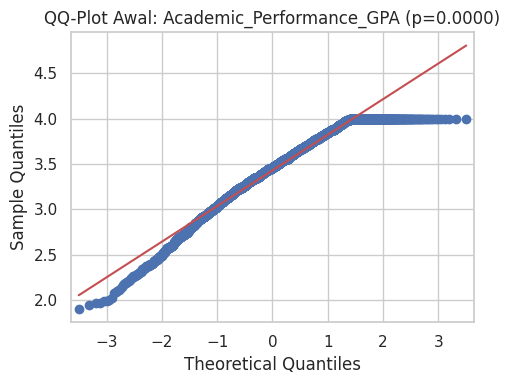


--- TRANSFORMASI DATA & UJI NORMALITAS ULANG ---

Evaluasi transformasi untuk variabel 'Age':
  - log10       : stat=0.9668, p-value=0.0000
  - ln          : stat=0.9668, p-value=0.0000
  - sqrt        : stat=0.9601, p-value=0.0000
  - square      : stat=0.9217, p-value=0.0000
  - reciprocal  : stat=0.9713, p-value=0.0000
=> Transformasi terbaik untuk 'Age': reciprocal (p=0.0000 -> Tetap Tidak Normal (Tolak H0))


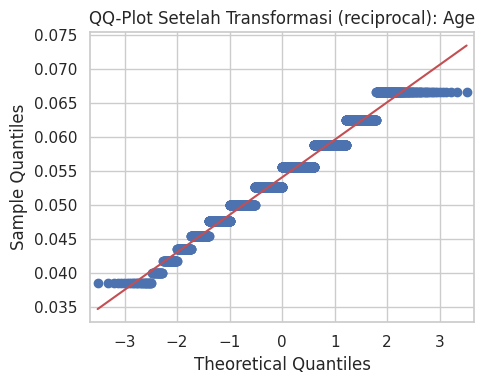


Evaluasi transformasi untuk variabel 'Daily_Usage_Hours':
  - log10       : stat=0.9966, p-value=0.0000
  - ln          : stat=0.9966, p-value=0.0000
  - sqrt        : stat=0.9768, p-value=0.0000
  - square      : stat=0.7435, p-value=0.0000
  - reciprocal  : stat=0.8837, p-value=0.0000
=> Transformasi terbaik untuk 'Daily_Usage_Hours': log10 (p=0.0000 -> Tetap Tidak Normal (Tolak H0))


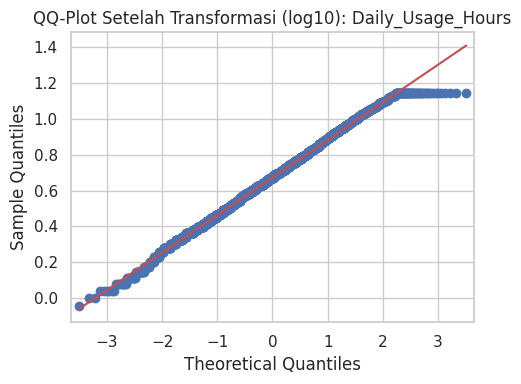


Evaluasi transformasi untuk variabel 'Weekend_Extra_Hours':
  - log10       : stat=0.9627, p-value=0.0000
  - ln          : stat=0.9627, p-value=0.0000
  - sqrt        : stat=0.9896, p-value=0.0000
  - square      : stat=0.9296, p-value=0.0000
  - reciprocal  : stat=0.8449, p-value=0.0000
=> Transformasi terbaik untuk 'Weekend_Extra_Hours': sqrt (p=0.0000 -> Tetap Tidak Normal (Tolak H0))


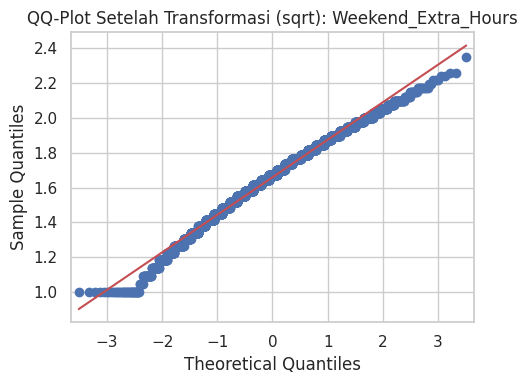


Evaluasi transformasi untuk variabel 'Sleep_Duration_Hours':
  - log10       : stat=0.9503, p-value=0.0000
  - ln          : stat=0.9503, p-value=0.0000
  - sqrt        : stat=0.9760, p-value=0.0000
  - square      : stat=0.9962, p-value=0.0000
  - reciprocal  : stat=0.8666, p-value=0.0000
=> Transformasi terbaik untuk 'Sleep_Duration_Hours': square (p=0.0000 -> Tetap Tidak Normal (Tolak H0))


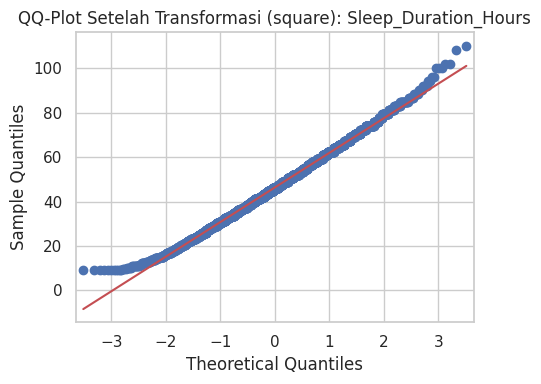


Evaluasi transformasi untuk variabel 'Sleep_Quality_Score':
  - log10       : stat=0.8534, p-value=0.0000
  - ln          : stat=0.8534, p-value=0.0000
  - sqrt        : stat=0.8859, p-value=0.0000
  - square      : stat=0.8516, p-value=0.0000
  - reciprocal  : stat=0.7505, p-value=0.0000
=> Transformasi terbaik untuk 'Sleep_Quality_Score': sqrt (p=0.0000 -> Tetap Tidak Normal (Tolak H0))


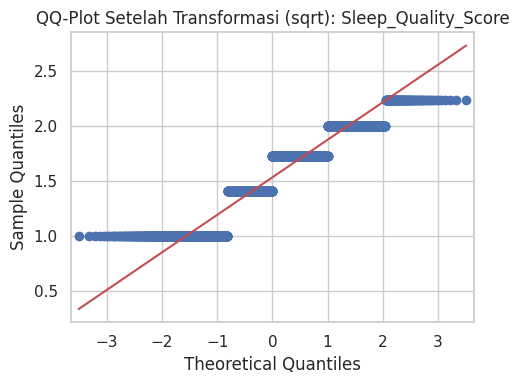


Evaluasi transformasi untuk variabel 'Perceived_Stress_Score':
  - log10       : stat=0.8893, p-value=0.0000
  - ln          : stat=0.8893, p-value=0.0000
  - sqrt        : stat=0.9894, p-value=0.0000
  - square      : stat=0.8077, p-value=0.0000
  - reciprocal  : stat=0.4137, p-value=0.0000
=> Transformasi terbaik untuk 'Perceived_Stress_Score': sqrt (p=0.0000 -> Tetap Tidak Normal (Tolak H0))


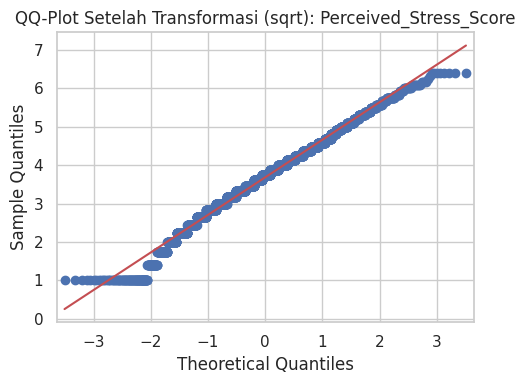


Evaluasi transformasi untuk variabel 'Mental_Health_Index':
  - log10       : stat=0.8932, p-value=0.0000
  - ln          : stat=0.8932, p-value=0.0000
  - sqrt        : stat=0.9255, p-value=0.0000
  - square      : stat=0.9748, p-value=0.0000
  - reciprocal  : stat=0.7995, p-value=0.0000
=> Transformasi terbaik untuk 'Mental_Health_Index': square (p=0.0000 -> Tetap Tidak Normal (Tolak H0))


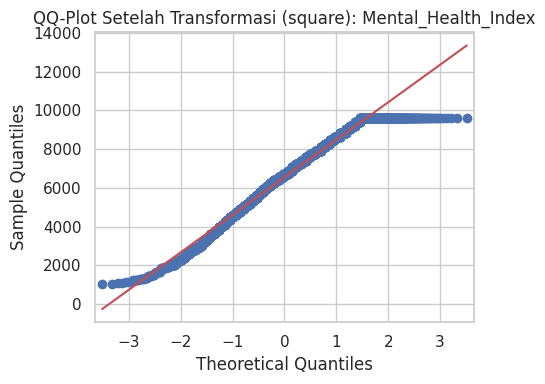


Evaluasi transformasi untuk variabel 'Academic_Performance_GPA':
  - log10       : stat=0.9350, p-value=0.0000
  - ln          : stat=0.9350, p-value=0.0000
  - sqrt        : stat=0.9507, p-value=0.0000
  - square      : stat=0.9763, p-value=0.0000
  - reciprocal  : stat=0.8907, p-value=0.0000
=> Transformasi terbaik untuk 'Academic_Performance_GPA': square (p=0.0000 -> Tetap Tidak Normal (Tolak H0))


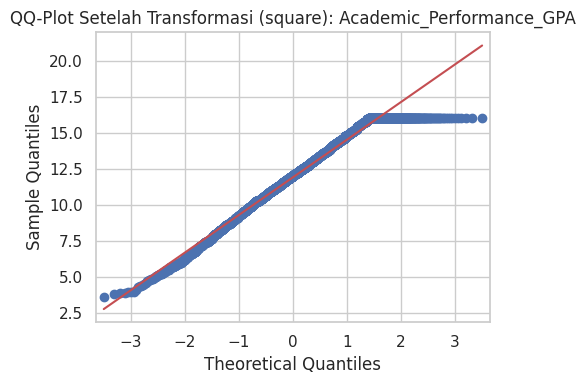

In [56]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import shapiro
from statsmodels.graphics.gofplots import qqplot
from google.colab import files

# 1. Load Dataset (cek lokal dulu, lalu fallback ke upload)
candidates = [
    "Social_media_impact_on_life.csv",
    "Social_media_impact_on_life_.csv",
    "/content/drive/MyDrive/Social_media_impact_on_life.csv",
    "/content/drive/MyDrive/Social_media_impact_on_life_.csv",
]

file_path = next((p for p in candidates if os.path.exists(p)), None)

if file_path is None:
    print("File belum ditemukan di direktori lokal. Silakan unggah file CSV:")
    uploaded = files.upload()
    if uploaded:
        file_path = next(iter(uploaded.keys()))
    else:
        raise FileNotFoundError("File CSV tidak ditemukan dan tidak ada file yang diunggah.")

df = pd.read_csv(file_path)
print("File berhasil dimuat:", file_path)
print("Ukuran data:", df.shape)
display(df.head())

# 2. Identifikasi Variabel Numerik (Kuantitatif)
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
print("\nVariabel numerik yang terdeteksi:", numeric_cols)

# 3. Uji Normalitas Shapiro-Wilk & QQ-Plot Awal (alpha = 0.05)
alpha = 0.05
non_normal_cols = []

print("\n--- HASIL UJI NORMALITAS AWAL (SHAPIRO-WILK) ---")
for col in numeric_cols:
    data_clean = df[col].dropna()
    if len(data_clean) < 3 or data_clean.nunique() <= 1:
        print(f"Variabel: {col} | Dilewati (jumlah data < 3 atau nilai konstan)")
        continue

    stat, p = shapiro(data_clean)
    status = "Normal (Terima H0)" if p > alpha else "Tidak Normal (Tolak H0)"
    print(f"Variabel: {col} | stat={stat:.4f}, p-value={p:.4f} -> {status}")

    if p <= alpha:
        non_normal_cols.append(col)

    fig, ax = plt.subplots(figsize=(5, 4))
    qqplot(data_clean, line="s", ax=ax)
    ax.set_title(f"QQ-Plot Awal: {col} (p={p:.4f})")
    plt.tight_layout()
    plt.show()

# 4. Transformasi Data untuk Variabel yang Tidak Normal & Uji Ulang
df_transformed = df.copy()

if len(non_normal_cols) == 0:
    print("\nSeluruh variabel kuantitatif sudah berdistribusi normal (atau tidak ada yang ditransformasi).")
else:
    print("\n--- TRANSFORMASI DATA & UJI NORMALITAS ULANG ---")
    for col in non_normal_cols:
        data_clean = df[col].dropna()

        shift = abs(data_clean.min()) + 1.0 if data_clean.min() <= 0 else 0.0
        shifted_data = data_clean + shift
        non_zero_shifted = shifted_data.replace(0, np.nan)

        transformations = {
            "log10": np.log10(non_zero_shifted),
            "ln": np.log(non_zero_shifted),
            "sqrt": np.sqrt(shifted_data),
            "square": np.power(data_clean, 2),
            "reciprocal": 1.0 / non_zero_shifted,
        }

        best_method = None
        best_p = -1.0
        best_series = None

        print(f"\nEvaluasi transformasi untuk variabel '{col}':")
        for method_name, trans_data in transformations.items():
            valid_trans = trans_data.replace([np.inf, -np.inf], np.nan).dropna()
            if len(valid_trans) < 3 or valid_trans.nunique() <= 1:
                print(f"  - {method_name:12s}: tidak valid / konstan")
                continue

            stat_t, p_t = shapiro(valid_trans)
            print(f"  - {method_name:12s}: stat={stat_t:.4f}, p-value={p_t:.4f}")

            if p_t > best_p:
                best_p = p_t
                best_method = method_name
                best_series = trans_data.replace([np.inf, -np.inf], np.nan)

        if best_method is not None and best_series is not None:
            new_col_name = f"{col}_trans_{best_method}"
            df_transformed[new_col_name] = best_series

            kesimpulan = "Normal (Terima H0)" if best_p > alpha else "Tetap Tidak Normal (Tolak H0)"
            print(f"=> Transformasi terbaik untuk '{col}': {best_method} (p={best_p:.4f} -> {kesimpulan})")

            fig, ax = plt.subplots(figsize=(5, 4))
            qqplot(best_series.dropna(), line="s", ax=ax)
            ax.set_title(f"QQ-Plot Setelah Transformasi ({best_method}): {col}")
            plt.tight_layout()
            plt.show()